# configuration & loadings

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.inspection import permutation_importance

plt.style.use("default")

In [ ]:
# Determine project root
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gvns").exists():
    PROJECT_ROOT = Path(__file__).parent.parent.parent.parent if '__file__' in locals() else Path.cwd().parent.parent.parent

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\HP\Documents\GitHub\GVNS-implementation


In [ ]:
DATA_PATH = PROJECT_ROOT / "gvns" / "datasets" / "ml_ls_data" / "learning_dataset.csv"
MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_delta_regressor.pkl"
FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_features.json"

# load artifacts
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

with open(FEATURES_PATH, "r") as f:
    feature_names = json.load(f)

print(f"Dataset shape: {df.shape}")
print(f"Number of features: {len(feature_names)}")

Dataset shape: (39889, 29)
Number of features: 26


# importance

In [ ]:
# prepare X and y
y = df["rel_delta"]

# features
X = df[feature_names]

# sanity check
assert X.shape[1] == len(feature_names)

## built-in RF importance

In [5]:
importances = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importances.head(15)

avg_delta_W           0.197948
max_delta_W           0.177549
penT_ratio            0.081106
ls_fail_ratio_W       0.080644
improv_rate_W         0.079063
stagnation_ls         0.070200
pen_ratio             0.067680
elapsed               0.034726
time_left_ratio       0.025968
time_elapsed_ratio    0.024043
PV                    0.023219
strategy              0.016379
early_tw_ratio        0.015399
gvns_iter             0.015316
n_customers           0.013194
dtype: float64

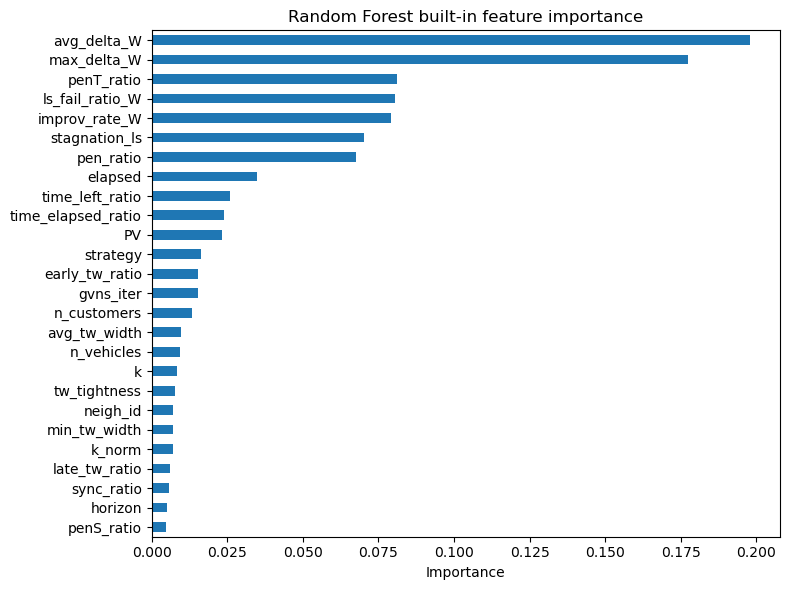

In [6]:
top_n = 20

plt.figure(figsize=(8, 6))
importances.iloc[::-1].plot(kind="barh")
plt.title("Random Forest built-in feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## permutation importance 

In [7]:
perm = permutation_importance(
    model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="neg_mean_squared_error"
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=feature_names
).sort_values(ascending=False)

perm_importance

max_delta_W           0.000243
avg_delta_W           0.000220
stagnation_ls         0.000175
ls_fail_ratio_W       0.000120
improv_rate_W         0.000109
penT_ratio            0.000099
pen_ratio             0.000086
PV                    0.000055
elapsed               0.000038
n_customers           0.000035
early_tw_ratio        0.000033
time_left_ratio       0.000026
time_elapsed_ratio    0.000023
strategy              0.000023
gvns_iter             0.000022
n_vehicles            0.000021
avg_tw_width          0.000013
neigh_id              0.000012
k_norm                0.000011
k                     0.000011
late_tw_ratio         0.000009
sync_ratio            0.000008
tw_tightness          0.000007
min_tw_width          0.000006
horizon               0.000005
penS_ratio            0.000004
dtype: float64

In [ ]:
perm_df = perm_importance.reset_index()
perm_df.columns = ["feature", "importance"]
perm_df

,feature,importance
0,max_delta_W,0.000243
1,avg_delta_W,0.000220
2,stagnation_ls,0.000175
3,ls_fail_ratio_W,0.000120
4,improv_rate_W,0.000109
5,penT_ratio,0.000099
6,pen_ratio,0.000086
7,PV,0.000055
8,elapsed,0.000038
9,n_customers,0.000035


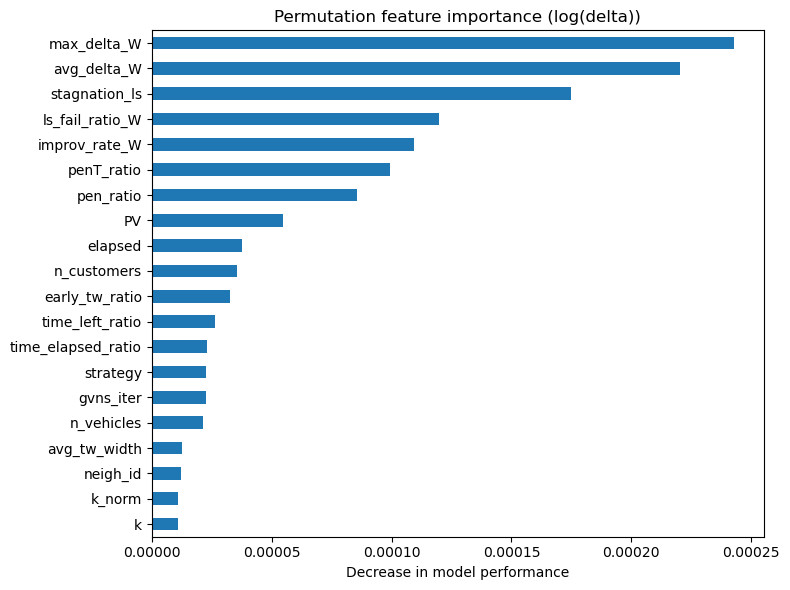

In [9]:
top_n = 20

plt.figure(figsize=(8, 6))
perm_importance.head(top_n).iloc[::-1].plot(kind="barh")
plt.title("Permutation feature importance (log(delta))")
plt.xlabel("Decrease in model performance")
plt.tight_layout()
plt.show()

### comparison 

In [10]:
comparison = pd.DataFrame({
    "rf_importance": importances,
    "perm_importance": perm_importance
}).sort_values("perm_importance", ascending=False)

comparison

,rf_importance,perm_importance
max_delta_W,0.177549,0.000243
avg_delta_W,0.197948,0.000220
stagnation_ls,0.070200,0.000175
ls_fail_ratio_W,0.080644,0.000120
improv_rate_W,0.079063,0.000109
penT_ratio,0.081106,0.000099
pen_ratio,0.067680,0.000086
PV,0.023219,0.000055
elapsed,0.034726,0.000038
n_customers,0.013194,0.000035


In [11]:
comp = comparison.reset_index()
comp.columns = ["feature", "rf_importance", "perm_importance"]
comp

,feature,rf_importance,perm_importance
0,max_delta_W,0.177549,0.000243
1,avg_delta_W,0.197948,0.000220
2,stagnation_ls,0.070200,0.000175
3,ls_fail_ratio_W,0.080644,0.000120
4,improv_rate_W,0.079063,0.000109
5,penT_ratio,0.081106,0.000099
6,pen_ratio,0.067680,0.000086
7,PV,0.023219,0.000055
8,elapsed,0.034726,0.000038
9,n_customers,0.013194,0.000035


## grouped importance 
its more "reasearch grade" 

In [12]:
FEATURE_GROUPS = {
    "search_dynamics": [
        "improv_rate_W",
        "avg_delta_W",
        "max_delta_W",
        "ls_fail_ratio_W",
        "time_left_ratio",
        "time_elapsed_ratio",
    ],
    "strategy_control": [
        "strategy",
        "k",
        "k_norm",
        "neigh_id",
    ],
    "instance_structure": [
        "tw_tightness",
        "avg_tw_width",
        "min_tw_width",
        "early_tw_ratio",
        "late_tw_ratio",
        "n_customers",
        "n_vehicles",
        "horizon",
        "sync_ratio",
    ],
    "penalties": [
        "pen_ratio",
        "penT_ratio",
        "penS_ratio",
    ],
}

group_importance = {}

for group, feats in FEATURE_GROUPS.items():
    feats = [f for f in feats if f in perm_importance]
    group_importance[group] = perm_importance[feats].sum()

grp_importance = pd.Series(group_importance).sort_values(ascending=False)
grp_importance

search_dynamics       0.000742
penalties             0.000189
instance_structure    0.000137
strategy_control      0.000057
dtype: float64

In [13]:
grp_df = grp_importance.reset_index()
grp_df.columns = ["groupe", "importance"]
grp_df

,groupe,importance
0,search_dynamics,0.000742
1,penalties,0.000189
2,instance_structure,0.000137
3,strategy_control,0.000057
